# PS10: Music Genre Classification using RNN (GTZAN)
Dataset: GTZAN (10 genres, 100 clips of 30s each).
Each clip is split into 10 segments of 3s; MFCCs are extracted for each segment.

In [1]:
import torch

MIN_TOTAL_VRAM_GB = 2.0
MIN_FREE_VRAM_GB = 1.0


def _gpu_fail(reason, fix):
    bar = '=' * 66
    raise RuntimeError(f'\n{bar}\nGPU CHECK FAILED - training was NOT started.\n{bar}\nProblem : {reason}\nFix     : {fix}\n{bar}')


if not torch.cuda.is_available():
    _gpu_fail('No CUDA GPU is visible to PyTorch (CPU runtime).',
              'Colab: Runtime > Change runtime type > T4 GPU, then Run all.\n          Local: install NVIDIA driver + CUDA-enabled PyTorch.')

props = torch.cuda.get_device_properties(0)
total_gb = props.total_memory / 1024**3
free_gb = torch.cuda.mem_get_info(0)[0] / 1024**3

if total_gb + 0.5 < MIN_TOTAL_VRAM_GB:
    _gpu_fail(f'{props.name} has {total_gb:.1f} GB VRAM; this notebook needs >= {MIN_TOTAL_VRAM_GB:.0f} GB.',
              'Use a Colab T4 (15 GB). Smaller cards can only run reduced settings.')

if free_gb < MIN_FREE_VRAM_GB:
    _gpu_fail(f'Only {free_gb:.1f} GB of {total_gb:.1f} GB VRAM is free (need {MIN_FREE_VRAM_GB:.1f} GB).',
              'Runtime > Restart session, close other GPU notebooks, then Run all again.')

print(f'GPU OK - {props.name} | {total_gb:.1f} GB total | {free_gb:.1f} GB free')

GPU OK - Tesla T4 | 14.6 GB total | 14.5 GB free


In [2]:
%pip install -q kagglehub librosa

import os
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings('ignore')

DATA_DIR = None
KAGGLE_DATASET = 'andradaolteanu/gtzan-dataset-music-genre-classification'
SR = 22050
SEGMENTS = 10
N_MFCC = 13
SEG_LEN = SR * 30 // SEGMENTS
EPOCHS = 40
SEED = 42

In [3]:
if DATA_DIR is None:
    try:
        import kagglehub
        DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as exc:
        print('=' * 66)
        print('DATASET DOWNLOAD FAILED')
        print('Option 1: add a Kaggle API token (Colab Secrets: KAGGLE_API_TOKEN).')
        print('Option 2: set DATA_DIR manually to a local copy of GTZAN.')
        print('=' * 66)
        raise SystemExit('Stopped: dataset not available.') from exc

root = Path(DATA_DIR)
matches = [p for p in root.rglob('genres_original') if p.is_dir()]
GENRES_DIR = matches[0] if matches else root / 'Data' / 'genres_original'
if not GENRES_DIR.is_dir():
    GENRES_DIR = root

genres = sorted([d.name for d in GENRES_DIR.iterdir() if d.is_dir()])
print('Genres:', genres)
print('Genres directory:', GENRES_DIR)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Genres directory: /kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original


In [4]:
def extract_mfcc(path):
    try:
        signal, _ = librosa.load(str(path), sr=SR, duration=30)
    except Exception:
        return None
    mfccs = []
    for s in range(SEGMENTS):
        seg = signal[s * SEG_LEN:(s + 1) * SEG_LEN]
        if len(seg) == SEG_LEN:
            mfcc = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC)
            mfccs.append(mfcc.T)
    return mfccs


files, labels = [], []
for label, genre in enumerate(genres):
    genre_dir = GENRES_DIR / genre
    for f in sorted(genre_dir.glob('*.wav')):
        files.append(f)
        labels.append(label)
print(f'Total valid files found: {len(files)}')

Total valid files found: 1000


In [5]:
f_train, f_test, l_train, l_test = train_test_split(
    files, labels, test_size=0.2, stratify=labels, random_state=SEED)

X_train, y_train = [], []
for path, label in zip(f_train, l_train):
    mfccs = extract_mfcc(path)
    if mfccs:
        X_train.extend(mfccs)
        y_train.extend([label] * len(mfccs))
X_train, y_train = np.array(X_train), np.array(y_train)

X_test, y_test = [], []
for path, label in zip(f_test, l_test):
    mfccs = extract_mfcc(path)
    if mfccs:
        X_test.extend(mfccs)
        y_test.extend([label] * len(mfccs))
X_test, y_test = np.array(X_test), np.array(y_test)

print(f'Train segments: {X_train.shape}, Test segments: {X_test.shape}')

Train segments: (7981, 130, 13), Test segments: (2000, 130, 13)


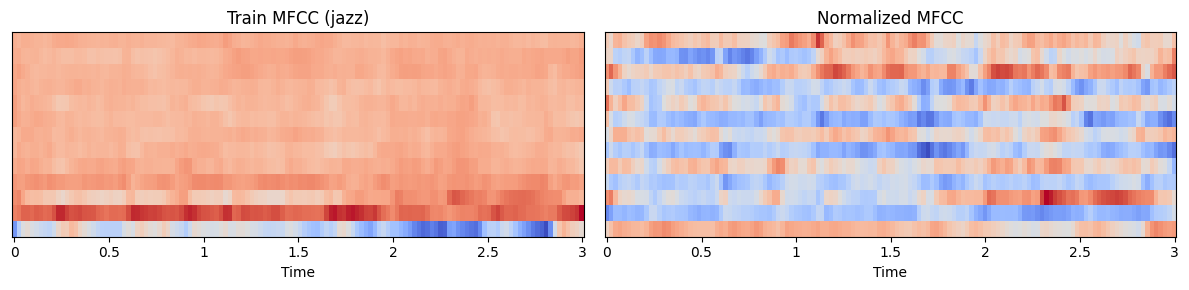

In [6]:
scaler = StandardScaler()
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_train_norm = scaler.fit_transform(X_train_flat).reshape(X_train.shape)

X_test_flat = X_test.reshape(X_test.shape[0], -1)
X_test_norm = scaler.transform(X_test_flat).reshape(X_test.shape)

plt.figure(figsize=(12, 3))
plt.subplot(1, 2, 1)
plt.title(f'Train MFCC ({genres[y_train[0]]})')
librosa.display.specshow(X_train[0].T, sr=SR, x_axis='time')
plt.subplot(1, 2, 2)
plt.title(f'Normalized MFCC')
librosa.display.specshow(X_train_norm[0].T, sr=SR, x_axis='time')
plt.tight_layout()
plt.show()

## Model

In [7]:
model = keras.Sequential([
    layers.Input((130, 13)),
    layers.SimpleRNN(128, return_sequences=True),
    layers.SimpleRNN(64),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(genres), activation='softmax'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 130, 128)       │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,338 (138.04 KB)

 Trainable params: 35,338 (138.04 KB)

 Non-trainable params: 0 (0.00 B)

## Training

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
]
history = model.fit(
    X_train_norm, y_train, validation_split=0.15,
    epochs=EPOCHS, batch_size=64, callbacks=callbacks, verbose=2)

Epoch 1/40
106/106 - 13s - 127ms/step - accuracy: 0.3431 - loss: 1.8700 - val_accuracy: 0.4140 - val_loss: 1.6860 - learning_rate: 0.0010
Epoch 2/40
106/106 - 2s - 23ms/step - accuracy: 0.4103 - loss: 1.6475 - val_accuracy: 0.4482 - val_loss: 1.6128 - learning_rate: 0.0010
Epoch 3/40
106/106 - 3s - 24ms/step - accuracy: 0.4483 - loss: 1.5705 - val_accuracy: 0.4249 - val_loss: 1.6749 - learning_rate: 0.0010
Epoch 4/40
106/106 - 2s - 22ms/step - accuracy: 0.4225 - loss: 1.6222 - val_accuracy: 0.4165 - val_loss: 1.6173 - learning_rate: 0.0010
Epoch 5/40

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
106/106 - 2s - 22ms/step - accuracy: 0.4417 - loss: 1.5526 - val_accuracy: 0.4048 - val_loss: 1.6383 - learning_rate: 0.0010
Epoch 6/40
106/106 - 2s - 22ms/step - accuracy: 0.4694 - loss: 1.4496 - val_accuracy: 0.4558 - val_loss: 1.5287 - learning_rate: 5.0000e-04
Epoch 7/40
106/106 - 2s - 22ms/step - accuracy: 0.4987 - loss: 1.4079 - val_accuracy: 0.4633 - val_lo

## Evaluation

Test accuracy (segment-level): 0.4905   Test loss: 1.4190


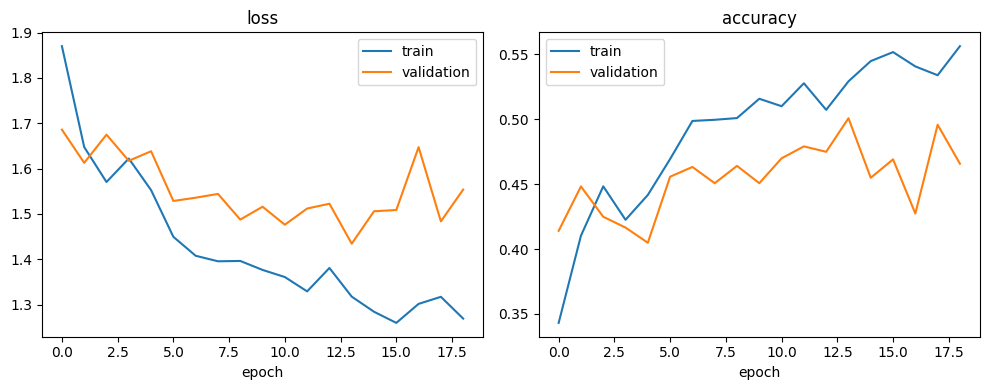

In [9]:
loss, acc = model.evaluate(X_test_norm, y_test, verbose=0)
print(f'Test accuracy (segment-level): {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       blues     0.4495    0.4450    0.4472       200
   classical     0.7778    0.9450    0.8533       200
     country     0.3333    0.2800    0.3043       200
       disco     0.3018    0.3350    0.3175       200
      hiphop     0.3636    0.4000    0.3810       200
        jazz     0.5000    0.6550    0.5671       200
       metal     0.7485    0.6400    0.6900       200
         pop     0.6287    0.6350    0.6318       200
      reggae     0.3831    0.3850    0.3840       200
        rock     0.3274    0.1850    0.2364       200

    accuracy                         0.4905      2000
   macro avg     0.4814    0.4905    0.4813      2000
weighted avg     0.4814    0.4905    0.4813      2000



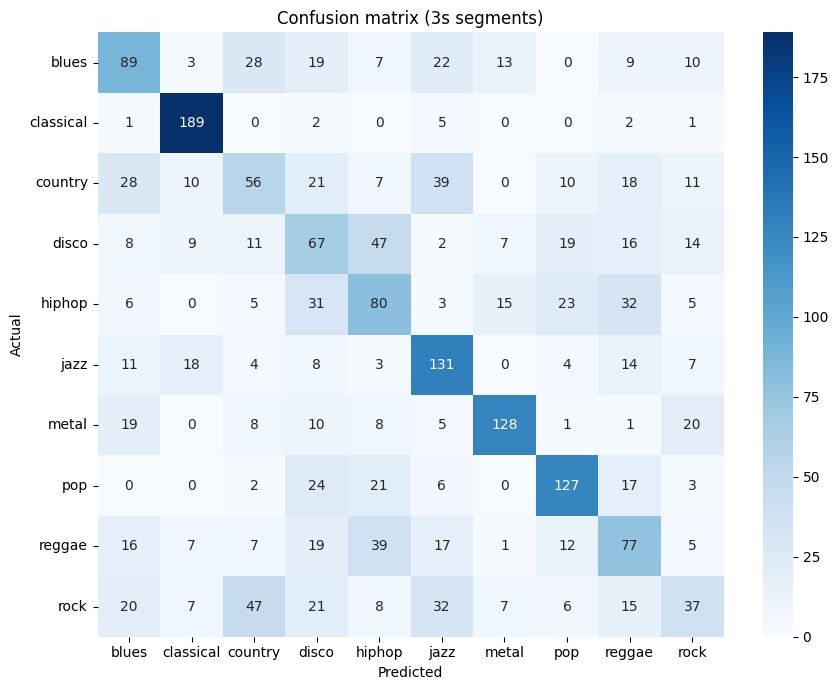

In [10]:
y_pred_seg = model.predict(X_test_norm, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred_seg, target_names=genres, digits=4, zero_division=0))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(y_test, y_pred_seg), annot=True, fmt='d', cmap='Blues',
            xticklabels=genres, yticklabels=genres)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix (3s segments)')
plt.tight_layout()
plt.show()

## Song-level prediction

In [11]:
def predict_song(path):
    mfccs = extract_mfcc(path)
    if not mfccs:
        return 'unreadable', 0.0
    X = np.array(mfccs)
    X_flat = X.reshape(X.shape[0], -1)
    X_norm = scaler.transform(X_flat).reshape(X.shape)
    probs = model.predict(X_norm, verbose=0).mean(axis=0)
    return genres[probs.argmax()], probs.max()


for path, label in list(zip(f_test, l_test))[:5]:
    genre, conf = predict_song(path)
    print(f'{path.name:20s} actual={genres[label]:10s} predicted={genre:10s} ({conf:.2f})')

classical.00071.wav  actual=classical  predicted=classical  (0.83)
blues.00092.wav      actual=blues      predicted=blues      (0.44)
metal.00070.wav      actual=metal      predicted=disco      (0.20)
jazz.00035.wav       actual=jazz       predicted=jazz       (0.57)
blues.00021.wav      actual=blues      predicted=blues      (0.63)


## Save model and scaler

In [12]:
import pickle

out_dir = Path('outputs')
out_dir.mkdir(exist_ok=True)
model.save(out_dir / 'gtzan_rnn.keras')
with open(out_dir / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print('Saved model and scaler to:', out_dir)

Saved model and scaler to: outputs
